# Real-Time Digital Quantum Simulation of the Schwinger Model under High-Field Laser Quenches
*Modeling Vacuum Breakdown and Pair Production for ELI-NP Physics Regimes using Qiskit and AerSimulator*

*Author: Boboc Alexandru-Florin*

### 1. Lattice Hamiltonian & Jordan-Wigner Mapping
The 1+1D Schwinger model (QED in one spatial and one temporal dimension) is discretized on a spatial lattice using the Kogut-Susskind staggered fermion formulation. Applying the Jordan-Wigner transformation maps the fermionic operators directly onto a chain of spin-1/2 qubits:

$$H_{\text{static}} = \frac{w}{2} \sum_{i=0}^{N-2} (X_i X_{i+1} + Y_i Y_{i+1}) + \frac{m}{2} \sum_{i=0}^{N-1} (-1)^i Z_i$$

where $w$ is the fermion hopping parameter, $m$ is the fermion mass, and the staggered phase $(-1)^i$ accounts for particle-antiparticle alternation on adjacent sites.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, partial_trace, entropy
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import SuzukiTrotter
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

# Parameters & Aer Simulator Configuration

N = 6             # Number of qubits (lattice sites)
m = 0.5           # Fermion mass
g = 1.0           # Gauge coupling
a = 1.0           # Lattice spacing
w = 1.0 / (2.0*a) # Hopping parameter

# Build a realistic noise model for AerSimulator
noise_model = NoiseModel()
error_1q = depolarizing_error(0.002, 1) # 0.2% error on 1-qubit gates
error_2q = depolarizing_error(0.015, 2) # 1.5% error on 2-qubit gates

noise_model.add_all_qubit_quantum_error(error_1q, ['u1', 'u2', 'u3', 'rz', 'sx', 'x'])
noise_model.add_all_qubit_quantum_error(error_2q, ['cx', 'ecr', 'cz', 'pauli_evolution'])

ideal_simulator = AerSimulator(method='statevector')
noisy_simulator = AerSimulator(noise_model=noise_model, method='density_matrix')

print(f"Confugured a noisy AerSimulator with depolarizing errors: 0.2% for single-qubit gates and 1.5% for two-qubit gates.")
print(f"Number of qubits: {N}, Fermion mass: {m}, Gauge coupling: {g}, Lattice spacing: {a}, Hopping parameter: {w}")

Confugured a noisy AerSimulator with depolarizing errors: 0.2% for single-qubit gates and 1.5% for two-qubit gates.
Number of qubits: 6, Fermion mass: 0.5, Gauge coupling: 1.0, Lattice spacing: 1.0, Hopping parameter: 0.5


In [2]:
# Hamiltonian Construction 

def build_schwinger_hamiltonian(N, m, w):
    pauli_terms = []
    for i in range(N - 1):
        x_term = ['I'] * N; x_term[i] = 'X'; x_term[i+1] = 'X'
        pauli_terms.append(("".join(x_term[::-1]), w / 2.0))
        y_term = ['I'] * N; y_term[i] = 'Y'; y_term[i+1] = 'Y'
        pauli_terms.append(("".join(y_term[::-1]), w / 2.0))
    for i in range(N):
        z_term = ['I'] * N; z_term[i] = 'Z'
        pauli_terms.append(("".join(z_term[::-1]), (m / 2.0) * ((-1)**i)))
    return SparsePauliOp.from_list(pauli_terms)

H_static = build_schwinger_hamiltonian(N, m, w)

def get_drive_operator(N):
    drive_terms = []
    for i in range(N):
        z_term = ['I'] * N; z_term[i] = 'Z'
        drive_terms.append(("".join(z_term[::-1]), float(i)))
    return SparsePauliOp.from_list(drive_terms)

H_drive = get_drive_operator(N)

def laser_field_envelope(t, E0=2.0, t0=5.0, sigma_t=1.5, omega_L=2.0):
    return E0 * np.exp(-((t - t0)**2) / (2.0 * sigma_t**2)) * np.cos(omega_L * t)

t_start, t_end, num_steps = 0.0, 10.0, 40  # Slightly reduced steps for efficiency with noise
times = np.linspace(t_start, t_end, num_steps)
dt = times[1] - times[0]

### 2. Quantum Quench & Time-Dependent Laser Field
To simulate vacuum destabilization under high-field laser regimes (such as those at ELI-NP), we introduce a time-dependent external electric field $E_{\text{ext}}(t)$ modeled as a Gaussian-envelope oscillating pulse:

$$E_{\text{ext}}(t) = E_0 \exp\left(-\frac{(t - t_0)^2}{2\sigma_t^2}\right) \cos(\omega_L t)$$

This couples to the lattice via a site-dependent driving operator $H_{\text{drive}} = \sum_n n Z_n$, modifying the instantaneous Hamiltonian as $H(t) = H_{\text{static}} + E_{\text{ext}}(t) H_{\text{drive}}$.

### 3. NISQ Simulation & Zero-Noise Extrapolation (ZNE)
On near-term quantum simulators or hardware with depolarizing noise channels ($\epsilon$), gate errors drive the system unphysically. We implement **Zero-Noise Extrapolation (ZNE)** by scaling the effective circuit depth (via circuit folding by scale factors $sf \in \{1, 3\}$) and performing a linear extrapolation back to the zero-noise limit ($\lambda \to 0$):

$$\langle O \rangle_{\text{ZNE}} = \lim_{\lambda \to 0} \langle O \rangle(\lambda)$$

In [3]:
# Noisy Simulation & ZNE (Zero-Noise Extrapolation) Setup

qc = QuantumCircuit(N)
for i in range(N):
    if i % 2 == 1: qc.x(i)  # Staggered vacuum state initialization

chiral_ideal = []
chiral_noisy = []
chiral_zne = []
entanglement_entropies = []
chiral_condensate_grid = []

scale_factors = [1, 3] # Noise scale factors for ZNE (increased circuit depth via folding)
trotter_synth = SuzukiTrotter(order=1)
subsystem_A = list(range(N // 2)) # Bipartition for entanglement entropy

print("Starting comparative simulation (Ideal vs Noisy vs ZNE)...")
for t in times:
    E_ext = laser_field_envelope(t)
    
    # Assemble Hamiltonian H(t) using native SparsePauliOp arithmetic
    H_t = H_static + E_ext * H_drive
    
    site_idx = N // 2
    
    # Ideal Run (Statevector)
    evo_gate_ideal = PauliEvolutionGate(H_t, time=dt, synthesis=trotter_synth)
    step_circ_id = QuantumCircuit(N); step_circ_id.append(evo_gate_ideal, range(N))
    
    # Transpile evolution part & append save instruction
    trans_id_part = transpile(step_circ_id, ideal_simulator)
    full_id_circ = qc.compose(trans_id_part)
    full_id_circ.save_statevector()
    
    res_id = ideal_simulator.run(full_id_circ).result()
    psi_id = res_id.get_statevector()
    
    z_op = np.array([[1, 0], [0, -1]])
    ops = [np.eye(2)] * N; ops[site_idx] = z_op
    full_z = ops[0]
    for op in ops[1:]: full_z = np.kron(op, full_z)
    
    val_id = np.real(np.vdot(psi_id.data, full_z @ psi_id.data))
    chiral_ideal.append(val_id)
    
    # Entanglement Entropy (Von Neumann) Tracking
    rho_A = partial_trace(psi_id, [i for i in range(N) if i not in subsystem_A])
    s_vn = entropy(rho_A, base=2)
    entanglement_entropies.append(s_vn)
    
    # Spatiotemporal Chiral Condensate Grid Tracking
    site_condensates = []
    for i in range(N):
        ops_i = [np.eye(2)] * N
        ops_i[i] = z_op
        full_z_i = ops_i[0]
        for op in ops_i[1:]: full_z_i = np.kron(op, full_z_i)
        exp_z_i = np.real(np.vdot(psi_id.data, full_z_i @ psi_id.data))
        chiral_i = ((-1)**i) * (exp_z_i + 1.0) / 2.0
        site_condensates.append(chiral_i)
    chiral_condensate_grid.append(site_condensates)
    
    # Noisy Run & ZNE (Zero-Noise Extrapolation)
    noisy_vals_for_zne = []
    for sf in scale_factors:
        # Scale effective time - depth to simulate increased noise levels
        evo_gate_noisy = PauliEvolutionGate(H_t, time=dt * sf, synthesis=trotter_synth)
        step_circ_ns = QuantumCircuit(N); step_circ_ns.append(evo_gate_noisy, range(N))
        
        # Transpile evolution circuit before adding simulator save commands
        trans_ns_part = transpile(step_circ_ns, noisy_simulator)
        full_ns_circ = qc.compose(trans_ns_part)
        full_ns_circ.save_density_matrix()
        
        res_ns = noisy_simulator.run(full_ns_circ).result()
        
        # Extract density matrix from result data dictionary
        dm_data = res_ns.data(full_ns_circ)['density_matrix']
        dm = np.array(dm_data)
        
        val_ns = np.real(np.trace(full_z @ dm))
        noisy_vals_for_zne.append(val_ns)
        
        if sf == 1:
            chiral_noisy.append(val_ns)
            
    # Linear ZNE extrapolation to lambda = 0
    if len(scale_factors) >= 2:
        coeffs_poly = np.polyfit(scale_factors, noisy_vals_for_zne, 1)
        val_zne = coeffs_poly[1] # Intercept at zero noise
    else:
        val_zne = noisy_vals_for_zne[0]
    chiral_zne.append(val_zne)
    
    # Advance base state with the current ideal step (ensures stable state continuity for the loop)
    qc = QuantumCircuit(N)
    qc.set_statevector(psi_id)

print("Simulation complete!")

Starting comparative simulation (Ideal vs Noisy vs ZNE)...
Simulation complete!


### 4. Quantum Diagnostics
To physically interpret the simulation results, we track two primary observables:
* **Von Neumann Entanglement Entropy ($S_{\text{vN}}$):** Computed via the reduced density matrix $\rho_A$ of a spatial bipartition ($S_{\text{vN}} = -\operatorname{Tr}(\rho_A \log_2 \rho_A)$), serving as a proxy for real pair creation and non-local information spreading.
* **Local Chiral Condensate ($\langle \bar{\psi}\psi \rangle_i$):** Mapped across all lattice sites to visualize site-resolved vacuum melting and symmetry restructuring.

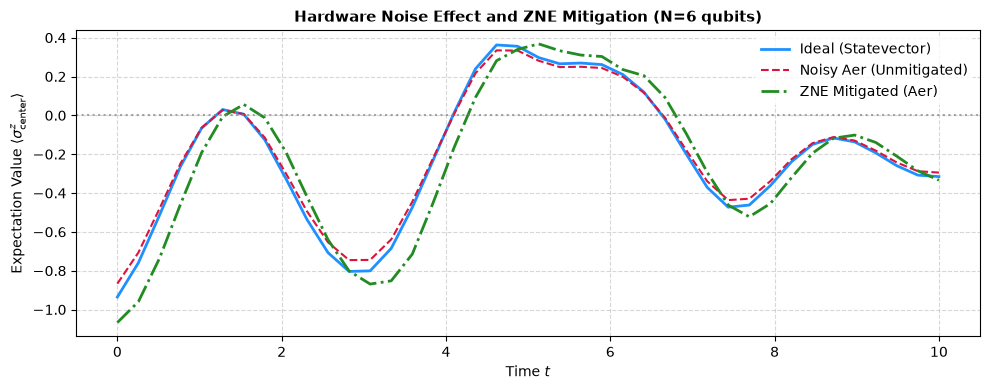

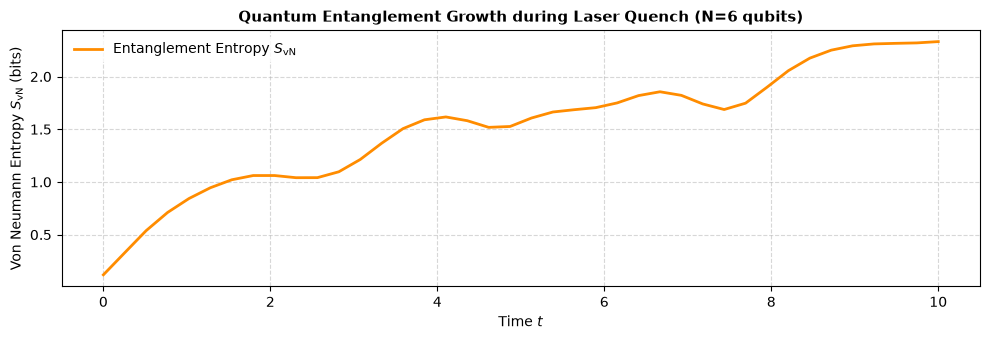

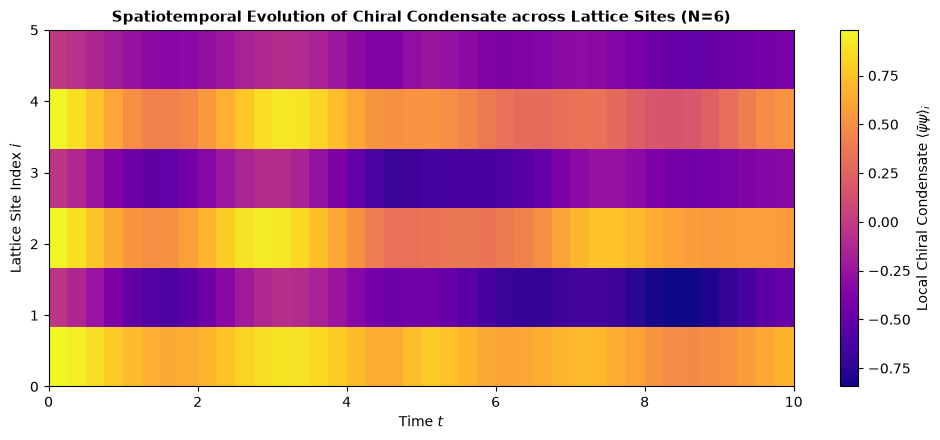

In [4]:
# Visualization & Plotting Results

# 1. Hardware Noise & ZNE Mitigation Plot
plt.figure(figsize=(10, 4))
plt.plot(times, chiral_ideal, label='Ideal (Statevector)', color='dodgerblue', linewidth=2)
plt.plot(times, chiral_noisy, label='Noisy Aer (Unmitigated)', color='crimson', linestyle='--', linewidth=1.5)
plt.plot(times, chiral_zne, label='ZNE Mitigated (Aer)', color='forestgreen', linestyle='-.', linewidth=2)
plt.title(f"Hardware Noise Effect and ZNE Mitigation (N={N} qubits)", fontsize=11, fontweight='bold')
plt.xlabel("Time $t$", fontsize=10)
plt.ylabel(r"Expectation Value $\langle \sigma^z_{\text{center}} \rangle$", fontsize=10)
plt.axhline(0, color='gray', linestyle=':', alpha=0.7)
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Entanglement Entropy Plot
plt.figure(figsize=(10, 3.5))
plt.plot(times, entanglement_entropies, label=r'Entanglement Entropy $S_{\text{vN}}$', color='darkorange', linewidth=2)
plt.title(f"Quantum Entanglement Growth during Laser Quench (N={N} qubits)", fontsize=11, fontweight='bold')
plt.xlabel("Time $t$", fontsize=10)
plt.ylabel(r"Von Neumann Entropy $S_{\text{vN}}$ (bits)", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

# 3. Spatiotemporal Chiral Condensate Heatmap
plt.figure(figsize=(10, 4.5))
heatmap_data = np.array(chiral_condensate_grid).T 
plt.imshow(heatmap_data, aspect='auto', origin='lower', extent=[times[0], times[-1], 0, N-1], cmap='plasma')
cbar = plt.colorbar()
cbar.set_label(r'Local Chiral Condensate $\langle \bar{\psi}\psi \rangle_i$', fontsize=10)
plt.title(f"Spatiotemporal Evolution of Chiral Condensate across Lattice Sites (N={N})", fontsize=11, fontweight='bold')
plt.xlabel("Time $t$", fontsize=10)
plt.ylabel("Lattice Site Index $i$", fontsize=10)
plt.yticks(range(N))
plt.tight_layout()
plt.show()